# DAY5 실습 02 — 공분산과 상관계수 : 피어슨 · 스피어만

In [ ]:
%pip install -q koreanize-matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from scipy import stats

In [ ]:
import os

from google.colab import drive

drive.mount("/content/drive")
data_folder = "/content/drive/MyDrive/HD-AI/data"
csv_path = os.path.join(data_folder, "ai4i2020.csv")

df = pd.read_csv(csv_path)

data = df.copy()

Mounted at /content/drive


## 데이터와 질문

데이터 파일 : `ai4i2020.csv`
출처 : UCI Machine Learning Repository - [AI4I 2020 Predictive Maintenance Dataset](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset)

한 행은 **운전 기록 1건**이다. 같은 행에 적힌 두 측정값을 **관측쌍** 하나로 본다.

| 원래 열 이름 | 바꾼 이름 | 뜻 | 단위 |
|---|---|---|---|
| Air temperature [K] | `air_temperature_k` | 공기온도 | K (켈빈) |
| Process temperature [K] | `process_temperature_k` | 공정온도 | K |
| Rotational speed [rpm] | `rotational_speed_rpm` | 회전수 | rpm (분당 회전수) |
| Torque [Nm] | `torque_nm` | 토크 | Nm (뉴턴미터) |
| Tool wear [min] | `tool_wear_min` | 공구 마모시간 | 분 |
| Type | `Type` (그대로) | 제품 유형 (L : 저품질, M : 중품질, H : 고품질) | 없음 |

**질문** : 두 변수가 함께 움직이는 정도를 숫자 하나로 어떻게 나타내는가? 피어슨과 스피어만은 무엇이 다른가?

**실습 전제** : AI4I는 제조 예지보전을 학습하도록 만든 합성 데이터다. 관측쌍끼리 서로 독립이라고 가정한다.

In [ ]:
raw = data.rename(columns={"Air temperature [K]": "air_temperature_k",       # 공기온도 (K)
                           "Process temperature [K]": "process_temperature_k",  # 공정온도 (K)
                           "Rotational speed [rpm]": "rotational_speed_rpm",    # 회전수 (rpm)
                           "Torque [Nm]": "torque_nm",                          # 토크 (Nm)
                           "Tool wear [min]": "tool_wear_min"})                 # 공구 마모시간 (분)

numeric_cols = ["air_temperature_k", "process_temperature_k", "rotational_speed_rpm", "torque_nm", "tool_wear_min"]
print("행·열:", raw.shape)
print(raw[numeric_cols].isna().sum())        # 열마다 결측(빈 값) 개수. 상관은 같은 행의 두 값으로 계산하므로 먼저 확인한다

행·열: (10000, 14)
air_temperature_k        0
process_temperature_k    0
rotational_speed_rpm     0
torque_nm                0
tool_wear_min            0
dtype: int64


## 1. 공분산에서 피어슨 상관계수로

**편차**는 값에서 평균을 뺀 것이다. **공분산**은 두 변수의 편차를 곱해(편차곱) 모두 더한 뒤 n − 1로 나눈 값이다.

공분산 = Σ(x − x의 평균)(y − y의 평균) ÷ (n − 1)

| 항목 | 내용 |
|---|---|
| 편차곱 | 두 값이 평균에서 같은 쪽으로 벗어나면 +, 반대쪽으로 벗어나면 − |
| 부호 | + 편차곱을 모두 더한 값이 양수다 / − 편차곱을 모두 더한 값이 음수다 |
| 크기 | 단위(x 단위 × y 단위)에 따라 달라진다 → 크기로 강도를 비교할 수 없다 |


공분산을 **x의 표준편차 × y의 표준편차**로 나누면 단위가 약분되고 값이 −1 ~ 1 사이로 정리된다. 이것이 **피어슨 상관계수** r이다.

r = 공분산 ÷ (x의 표준편차 × y의 표준편차)

| 비교 | 공분산 | 상관계수 r |
|---|---|---|
| 알려 주는 것 | 방향 (+ / −) | 방향 + 강도 |
| 단위 | x 단위 × y 단위 | 없음 |
| 값의 범위 | 제한 없음 | −1 ~ 1 |
| 크기로 강도 비교 | 할 수 없다 | 할 수 있다 |
| 공통 한계 | 직선 관계만 확인 | 직선 관계만 확인 → 산점도로 확인 |

| 함수 | 기능 |
|---|---|
| `x.cov(y)` | 두 열의 공분산 |
| `x.corr(y)` | 피어슨 상관계수 r. 결측이 있으면 그 쌍을 빼고 계산한다 |
| `stats.pearsonr(x, y)` | 피어슨 상관계수와 검정 결과. `.statistic`이 r이다 |

공식 문서 : [pandas.Series.cov](https://pandas.pydata.org/docs/reference/api/pandas.Series.cov.html) · [pandas.Series.corr](https://pandas.pydata.org/docs/reference/api/pandas.Series.corr.html) · [scipy.stats.pearsonr](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html)

In [ ]:
# [예제] AI4I 세 쌍의 공분산과 상관계수를 나란히 본다
pairs = [("air_temperature_k", "process_temperature_k", "공기온도 · 공정온도"),
         ("rotational_speed_rpm", "torque_nm", "회전수 · 토크"),
         ("tool_wear_min", "torque_nm", "공구마모 · 토크")]
for col_x, col_y, name in pairs:                      # 세 쌍을 하나씩 꺼내 같은 계산을 반복한다
    pair = raw[[col_x, col_y]].dropna()               # 두 변수 중 하나라도 결측값이 있는 행을 제외해 관측쌍을 유지
    print(name, "→ 공분산:", round(pair[col_x].cov(pair[col_y]), 2), "/ r:", round(pair[col_x].corr(pair[col_y]), 3))

# [결과]
# - 공기온도 · 공정온도 : 공분산 +2.6, r = 0.876 → 강한 양의 선형 관계
# - 회전수 · 토크 : 공분산 −1,563.91, r = −0.875 → 강한 음의 선형 관계
# - 공구마모 · 토크 : 공분산 −1.96, r = −0.003 → 선형 관계가 거의 없음
#
# - 공분산의 부호로 관계의 방향(양의 관계·음의 관계)을 확인할 수 있다.
# - 공분산의 크기로는 관계의 강도를 비교할 수 없다.
# - 관계의 방향과 강도를 비교할 때는 피어슨 상관계수(r)를 사용한다.

공기온도 · 공정온도 → 공분산: 2.6 / r: 0.876
회전수 · 토크 → 공분산: -1563.91 / r: -0.875
공구마모 · 토크 → 공분산: -1.96 / r: -0.003


**단위 바꾸기** : 회전수는 **분당 회전수**(rpm, 1분 동안 도는 횟수)로 기록되어 있다. 1분은 60초이므로 60으로 나누면 **초당 회전수**(1초 동안 도는 횟수)가 된다.

| 단위 | 뜻 | 1,500 rpm일 때 |
|---|---|---|
| 분당 회전수 (rpm) | 1분 동안 도는 횟수 | 1분에 1,500번 |
| 초당 회전수 | 1초 동안 도는 횟수 = rpm ÷ 60 | 1,500 ÷ 60 = 1초에 25번 |

In [ ]:
# [예제] 회전수 단위를 분당 → 초당으로 바꾸면 공분산과 r 은 어떻게 되는가
speed_pair = raw[["rotational_speed_rpm", "torque_nm"]].dropna()
speed = speed_pair["rotational_speed_rpm"]          # 분당 회전수 (rpm)
torque = speed_pair["torque_nm"]
speed_sec = speed / 60                              # 초당 회전수 = 분당 회전수 ÷ 60

print("회전수 앞 3건 (분당):", speed.head(3).tolist())
print("회전수 앞 3건 (초당):", speed_sec.head(3).round(2).tolist())
print("공분산 (분당 회전수 · 토크):", round(speed.cov(torque), 1))
print("공분산 (초당 회전수 · 토크):", round(speed_sec.cov(torque), 2))
print("상관계수 (분당):", round(speed.corr(torque), 3), "/ (초당):", round(speed_sec.corr(torque), 3))

# [결과]
# - 첫 기록 1,551 rpm(1분에 1,551번) → 1초에 25.85번. 같은 기록을 단위만 바꿔 적었다
# - 공분산 −1,563.9 → −26.07 로 60분의 1 이 되었다. 편차가 모두 60분의 1 이 되기 때문이다
# - 상관계수는 두 경우 모두 −0.875 로 같다 → 공분산 크기로는 관계의 강도를 비교할 수 없다

회전수 앞 3건 (분당): [1551, 1408, 1498]
회전수 앞 3건 (초당): [25.85, 23.47, 24.97]
공분산 (분당 회전수 · 토크): -1563.9
공분산 (초당 회전수 · 토크): -26.07
상관계수 (분당): -0.875 / (초당): -0.875


In [ ]:
# [예제] 공기온도 · 공정온도의 공분산을 두 표준편차로 나눠 r 을 구하고, 함수 결과와 비교한다
temp_pair = raw[["air_temperature_k", "process_temperature_k"]].dropna()
x = temp_pair["air_temperature_k"]
y = temp_pair["process_temperature_k"]

temp_cov = x.cov(y)                                   # 공분산 (단위 K × K)
print("공분산:", round(temp_cov, 3))
print("표준편차 x:", round(x.std(), 3), "/ y:", round(y.std(), 3))     # .std() : 표본표준편차
print("공분산 ÷ (표준편차 × 표준편차):", round(temp_cov / (x.std() * y.std()), 3))

print("corr():", round(x.corr(y), 3))
temp_result = stats.pearsonr(x, y)                    # 결과가 묶음으로 나온다
print("pearsonr().statistic:", round(temp_result.statistic, 3))

# [결과]
# - 공분산 2.600, 표준편차 2.000 K · 1.484 K
# - 2.600 ÷ (2.000 × 1.484) = 0.876 → corr() 와 pearsonr() 의 r 0.876 과 같다
# - 부호 + 는 공분산에서 왔고, 나누기로 단위가 사라져 강도를 비교할 수 있는 숫자가 되었다

공분산: 2.6
표준편차 x: 2.0 / y: 1.484
공분산 ÷ (표준편차 × 표준편차): 0.876
corr(): 0.876
pearsonr().statistic: 0.876


## 2. 스피어만 상관계수 : 값 대신 순위

**스피어만 상관계수** ρs는 값을 순위(가장 작은 값 1등, 다음 2등 …)로 바꾼 뒤 구한 피어슨 상관계수다. 직선이 아니어도 한쪽이 커질 때 다른 쪽이 계속 커지거나 계속 작아지면 1(또는 −1)에 가깝다. 이렇게 한 방향으로만 변하는 관계를 **단조 관계**라고 한다.

| 비교 | 피어슨 r | 스피어만 ρs |
|---|---|---|
| 보는 관계 | 직선 관계 | 한 방향으로 계속 커지거나 작아지는 관계 (단조 관계) |
| 계산에 쓰는 값 | 원래 값 | 순위 |
| 한 방향 곡선일 때 | 1보다 작게 나온다 | 1에 가깝게 나온다 |
| U자처럼 방향이 바뀔 때 | 0에 가깝게 나올 수 있다 | 0에 가깝게 나올 수 있다 |

| 함수 | 기능 |
|---|---|
| `rank()` | 값마다 순위를 매긴다 (작은 값이 1) |
| `stats.spearmanr(x, y)` | 스피어만 상관계수와 검정 결과. `.statistic`이 ρs다 |
| `x.corr(y, method="spearman")` | 스피어만 상관계수 하나만 돌려준다 |

공식 문서 : [scipy.stats.spearmanr](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html) · [pandas.Series.rank](https://pandas.pydata.org/docs/reference/api/pandas.Series.rank.html)

In [ ]:
# [예제] 한 방향으로 빠르게 늘어나는 다섯 점에서 피어슨과 스피어만을 비교한다 (설명용 숫자)
curve = pd.DataFrame({"x": [1, 2, 3, 4, 5],
                      "y": [1, 2, 4, 8, 16]})      # y 가 두 배씩 늘어난다 : 순서는 일정, 간격은 점점 커진다
curve["x 순위"] = curve["x"].rank()
curve["y 순위"] = curve["y"].rank()
print(curve)

print("피어슨 r:", round(stats.pearsonr(curve["x"], curve["y"]).statistic, 3))
print("스피어만 ρs:", round(stats.spearmanr(curve["x"], curve["y"]).statistic, 3))
print("순위끼리 구한 피어슨:", round(curve["x 순위"].corr(curve["y 순위"]), 3))

# [결과]
# - 값으로 보면 직선에서 벗어나 피어슨 r = 0.933
# - 순위로 보면 1 · 2 · 3 · 4 · 5 로 x 순위와 똑같아 스피어만 ρs = 1.000
# - 스피어만은 '순위로 바꾼 값의 피어슨'과 같다 (1.000)

   x   y  x 순위  y 순위
0  1   1   1.0   1.0
1  2   2   2.0   2.0
2  3   4   3.0   3.0
3  4   8   4.0   4.0
4  5  16   5.0   5.0
피어슨 r: 0.933
스피어만 ρs: 1.0
순위끼리 구한 피어슨: 1.0


## 3. 피어슨과 스피어만의 선택 기준

상관계수는 **자료의 척도와 산점도 모양**을 보고 선택한다.

**척도**는 값이 무엇을 나타내는지에 따라 나눈 자료의 종류다.

| 척도 | 뜻 | 예 | 상관계수 |
|---|---|---|---|
| 수치형 (연속형) | 측정한 크기. 값 사이 간격이 의미 있다 | 온도, 회전수, 토크 | 산점도 모양으로 피어슨 · 스피어만을 고른다 |
| 순서형 | 순서만 의미 있다. 1점과 2점 차이가 4점과 5점 차이와 같다고 보장할 수 없다 | 만족도 1 ~ 5점, 품질 등급 | 스피어만 |
| 명목형 | 순서 없는 구분 | 제품 유형 L · M · H, 라인 | 상관계수를 쓰지 않는다 → 카이제곱 독립성 검정 |

| 산점도 · 자료 | 선택 |
|---|---|
| 두 변수가 수치형이고 산점도가 직선 | 피어슨 |
| 한 방향으로 변하는 곡선, 또는 순서형 자료 (만족도 1 ~ 5점 등) | 스피어만 |



In [ ]:
# [예제] 회전수 · 토크에서 두 계수를 함께 구하고 산점도 모양과 연결한다
speed_pearson = stats.pearsonr(speed, torque).statistic       # speed, torque : 1절에서 만든 회전수 · 토크 관측쌍
speed_spearman = stats.spearmanr(speed, torque).statistic
print("피어슨 r:", round(speed_pearson, 3))
print("스피어만 ρs:", round(speed_spearman, 3))
print("절댓값 차이:", round(abs(speed_spearman) - abs(speed_pearson), 3))

# [결과]
# - 피어슨 −0.875, 스피어만 −0.916 → 둘 다 강한 음의 관계
# - 스피어만의 절댓값이 0.041 더 크다 → 순서는 잘 지켜지지만 직선에서는 벗어난다는 신호
# - 산점도의 '완만하게 휜 곡선'과 맞는다. 결과에는 두 계수와 곡선 모양을 함께 적는다

피어슨 r: -0.875
스피어만 ρs: -0.916
절댓값 차이: 0.041


## 4. 이상값이 상관계수에 미치는 영향

피어슨은 원래 값의 편차를 곱하므로, 멀리 떨어진 점 하나가 결과를 크게 흔든다. 스피어만은 순위를 쓰므로 덜 흔들리지만 영향이 없는 것은 아니다.


점 5개 → 피어슨: -1.0 / 스피어만: -1.0
한 점 추가 → 피어슨: 0.92 / 스피어만: -0.14


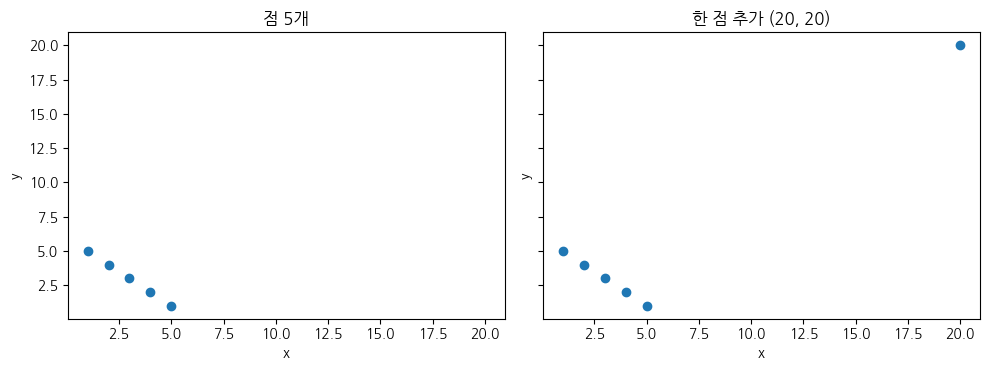

In [ ]:
# [예제] 점 5개에 멀리 떨어진 점 1개를 더하면 두 계수가 어떻게 바뀌는가 (설명용 숫자)
base = pd.DataFrame({"x": [1, 2, 3, 4, 5], "y": [5, 4, 3, 2, 1]})              # x 가 늘면 y 가 줄어드는 5점
added = pd.DataFrame({"x": [1, 2, 3, 4, 5, 20], "y": [5, 4, 3, 2, 1, 20]})     # 같은 5점 + 멀리 떨어진 점 (20, 20) 하나

for name, sample in [("점 5개", base), ("한 점 추가", added)]:
    print(name, "→ 피어슨:", round(sample["x"].corr(sample["y"]), 2),
          "/ 스피어만:", round(sample["x"].corr(sample["y"], method="spearman"), 2))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True, sharey=True)   # 두 그림의 축 범위를 같게
axes[0].scatter(base["x"], base["y"])
axes[0].set(title="점 5개", xlabel="x", ylabel="y")
axes[1].scatter(added["x"], added["y"])
axes[1].set(title="한 점 추가 (20, 20)", xlabel="x", ylabel="y")
plt.tight_layout()
plt.show()

# [결과]
# - 점 5개 : 피어슨 −1.00, 스피어만 −1.00
# - 한 점 추가 : 피어슨 +0.92 로 부호가 뒤집혔고, 스피어만은 −0.14 로 음의 방향을 유지했다
# - 이상값 하나에 피어슨 상관계수가 바뀐다,  그래서 산점도를 먼저 보고 두 계수를 함께 계산한다

In [ ]:
# [실습]
# 상황 : 공기온도 · 공정온도는 산점도가 직선이었다. 두 계수를 함께 구해 산점도 모양과 맞는지 확인한다.
# 1절의 x, y(공기온도 · 공정온도)로 피어슨 r 과 스피어만 ρs 를 구하고, 두 값의 차이로 무엇을 말할 수 있는지 쓰시오.




# - 피어슨 0.876, 스피어만 0.864 → 둘 다 강한 양의 관계이고 차이가 작다
# - 회전수 · 토크와 달리 스피어만이 더 크지 않다. 산점도의 직선 모양과 맞으므로(1장에서 확인) 피어슨으로 요약한다
# - 다만 두 값이 비슷하다는 것만으로 직선임이 증명되지는 않는다. 모양은 산점도로 확인한다

## 5. 정리 : 공분산 · 피어슨 · 스피어만

| 구분 | 공분산 | 피어슨 r | 스피어만 ρs |
|---|---|---|---|
| 계산 | 편차곱의 합 ÷ (n − 1) | 공분산 ÷ (두 표준편차의 곱) | 순위로 바꾼 값의 피어슨 |
| 알려 주는 것 | 방향 | 직선 관계의 방향 · 강도 | 단조 관계의 방향 · 강도 |
| 범위 · 단위 | 제한 없음 · x 단위 × y 단위 | −1 ~ 1 · 없음 | −1 ~ 1 · 없음 |
| 코드 | `표[["x", "y"]].cov()` | `x.corr(y)` · `stats.pearsonr(x, y)` | `x.corr(y, method="spearman")` · `stats.spearmanr(x, y)` |

### 해석 시 유의점

- 공분산의 부호는 편차곱을 모두 더한 값으로 정해진다. 점의 개수만이 아니라 평균에서 떨어진 거리도 반영된다
- 공분산 크기는 단위에 따라 바뀌므로 강도 비교에는 상관계수를 쓴다
- 상관계수는 자료의 척도와 산점도 모양을 보고 고른다
- 두 계수의 차이가 크면 산점도로 돌아가 곡선 · 이상값을 확인한다
- 이상값은 원인을 먼저 확인하고, 두 계수를 함께 보고한다